In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [4]:
df=pd.read_csv(r'C:\Users\smk25\OneDrive\Documents\Customer Segmentation for Targeted Marketing\dataset\cleaned_customer_data.csv')
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,0,0,0,0,0,3,11,1,57
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,0,0,0,0,3,11,0,60
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,0,0,0,0,3,11,0,49
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,0,0,0,0,3,11,0,30
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,0,0,0,0,3,11,0,33


In [44]:
df.shape

(2236, 30)

In [ ]:
Customer Demographics Analysis

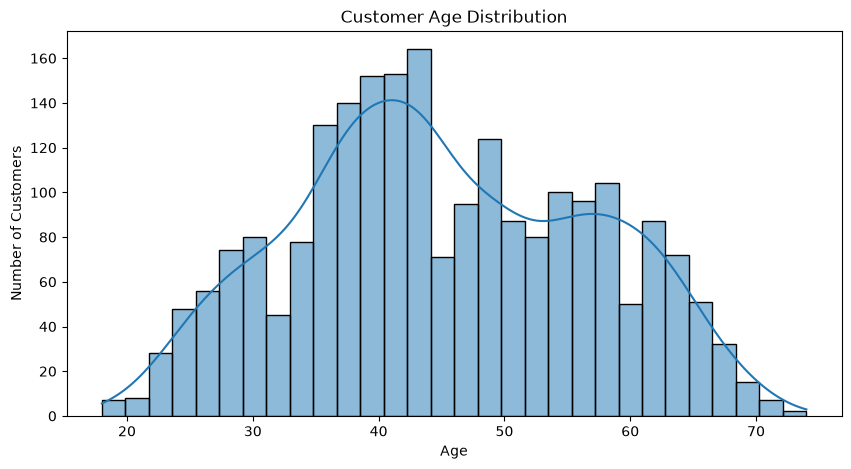

In [45]:
#Age distribution
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='Age', bins=30, kde=True)

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

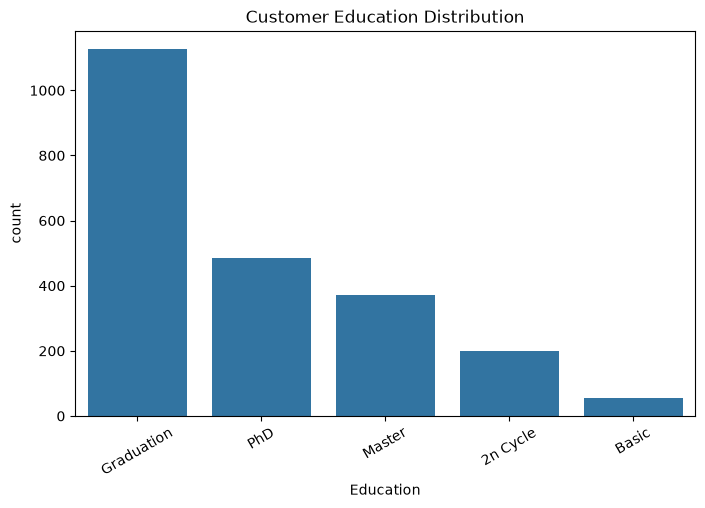

In [46]:
#Education distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Education',
              order=df['Education'].value_counts().index)

plt.title('Customer Education Distribution')
plt.xticks(rotation=30)

plt.show()

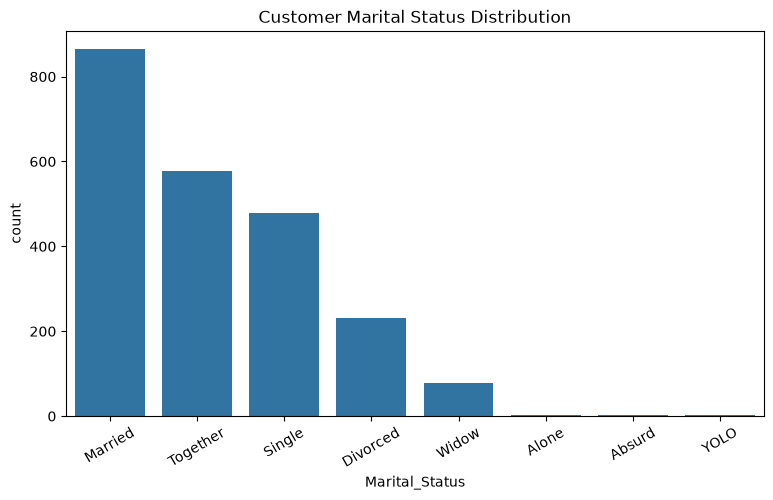

In [47]:
#Marital status distribution
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x='Marital_Status',
              order=df['Marital_Status'].value_counts().index)

plt.title('Customer Marital Status Distribution')
plt.xticks(rotation=30)

plt.show()

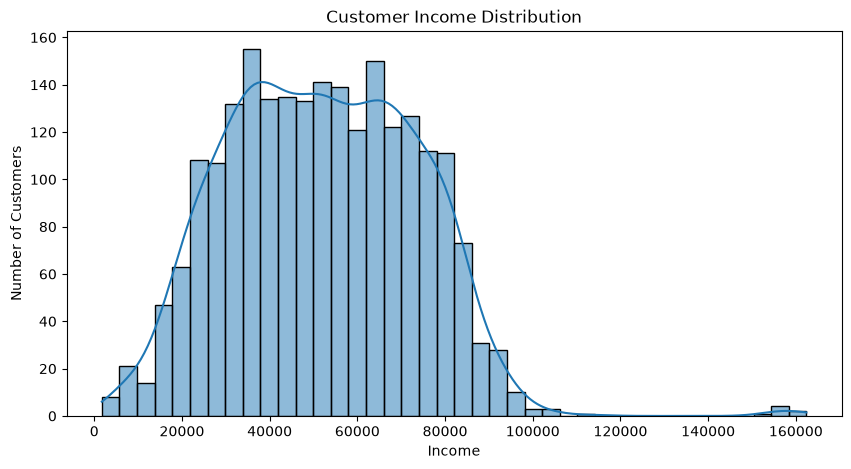

In [48]:
#Income Analysis
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='Income', bins=40, kde=True)

plt.title('Customer Income Distribution')
plt.xlabel('Income')
plt.ylabel('Number of Customers')

plt.show()

In [49]:
df['Income'].describe()

count      2236.000000
mean      51952.614043
std       21411.466851
min        1730.000000
25%       35502.500000
50%       51381.500000
75%       68275.750000
max      162397.000000
Name: Income, dtype: float64

In [50]:
#Customer Spending Analysis
spending_columns = [
    'MntWines',
    'MntFruits',
    'MntMeatProducts',
    'MntFishProducts',
    'MntSweetProducts',
    'MntGoldProds'
]

df['Total_Spending'] = df[spending_columns].sum(axis=1)

df[['ID', 'Total_Spending']].head()

,ID,Total_Spending
0,5524,1617
1,2174,27
2,4141,776
3,6182,53
4,5324,422


In [51]:
avg_spending = df[spending_columns].mean().sort_values(
    ascending=False
)

print(avg_spending)

MntWines            304.127460
MntMeatProducts     166.983453
MntGoldProds         43.983005
MntFishProducts      37.536225
MntSweetProducts     27.080501
MntFruits            26.275939
dtype: float64


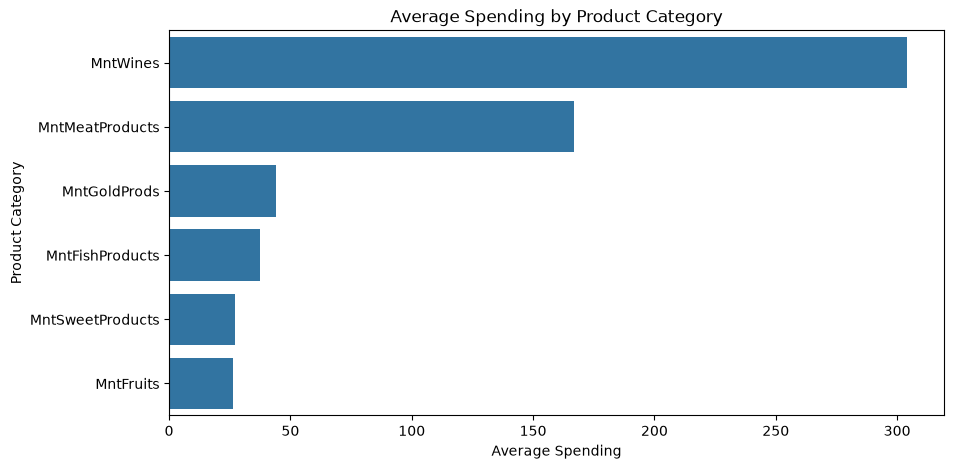

In [52]:
plt.figure(figsize=(10, 5))

sns.barplot(x=avg_spending.values,
            y=avg_spending.index)

plt.title('Average Spending by Product Category')
plt.xlabel('Average Spending')
plt.ylabel('Product Category')

plt.show()

In [53]:
#Marketing Campaign Analysis
campaign_columns = [
    'AcceptedCmp1',
    'AcceptedCmp2',
    'AcceptedCmp3',
    'AcceptedCmp4',
    'AcceptedCmp5',
    'Response'
]

campaign_acceptance = df[campaign_columns].sum()

print(campaign_acceptance)

AcceptedCmp1    144
AcceptedCmp2     30
AcceptedCmp3    163
AcceptedCmp4    167
AcceptedCmp5    162
Response        334
dtype: int64


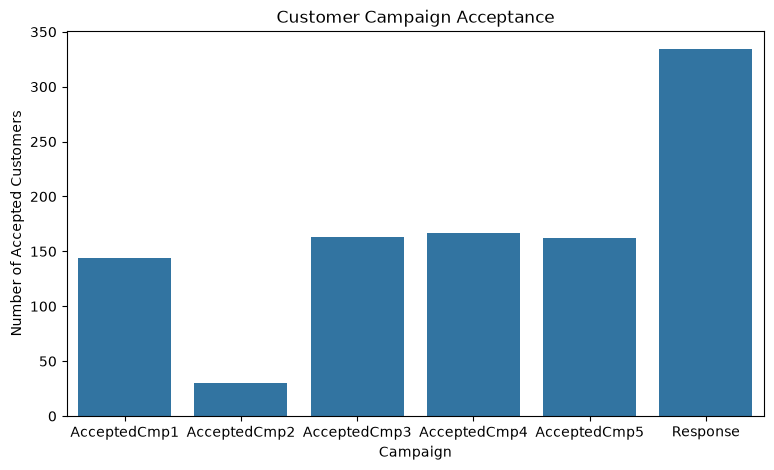

In [54]:
plt.figure(figsize=(9, 5))

sns.barplot(x=campaign_acceptance.index,
            y=campaign_acceptance.values)

plt.title('Customer Campaign Acceptance')
plt.xlabel('Campaign')
plt.ylabel('Number of Accepted Customers')

plt.show()

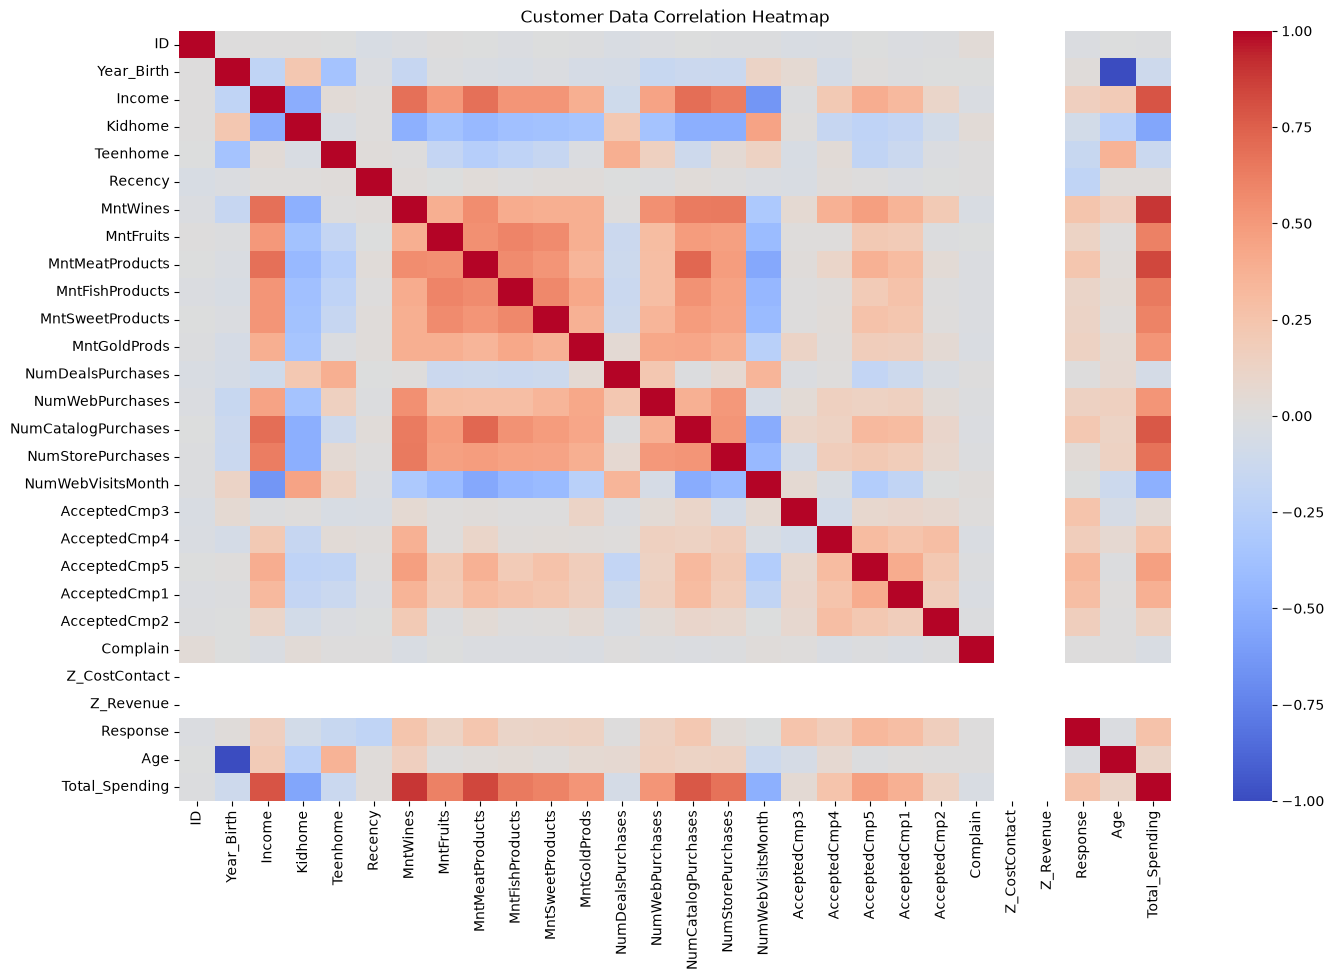

In [55]:
#Correlation Analysis
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(16, 10))

sns.heatmap(
    numeric_df.corr(),
    cmap='coolwarm',
    annot=False
)

plt.title('Customer Data Correlation Heatmap')

plt.show()

In [6]:
# Spending columns
spending_columns = [
    'MntWines',
    'MntFruits',
    'MntMeatProducts',
    'MntFishProducts',
    'MntSweetProducts',
    'MntGoldProds'
]

# Purchase columns
purchase_columns = [
    'NumWebPurchases',
    'NumCatalogPurchases',
    'NumStorePurchases',
    'NumDealsPurchases'
]

# Campaign columns
campaign_columns = [
    'AcceptedCmp1',
    'AcceptedCmp2',
    'AcceptedCmp3',
    'AcceptedCmp4',
    'AcceptedCmp5',
    'Response'
]

In [7]:
# Demographic summary
print(df['Age'].describe())
print(df['Income'].describe())

# Spending summary
print(df[spending_columns].mean().sort_values(ascending=False))

# Purchase summary
print(df[purchase_columns].mean().sort_values(ascending=False))

# Campaign summary
print(df[campaign_columns].sum().sort_values(ascending=False))

count    2236.000000
mean       45.101968
std        11.703281
min        18.000000
25%        37.000000
50%        44.000000
75%        55.000000
max        74.000000
Name: Age, dtype: float64
count      2236.000000
mean      51952.614043
std       21411.466851
min        1730.000000
25%       35502.500000
50%       51381.500000
75%       68275.750000
max      162397.000000
Name: Income, dtype: float64
MntWines            304.127460
MntMeatProducts     166.983453
MntGoldProds         43.983005
MntFishProducts      37.536225
MntSweetProducts     27.080501
MntFruits            26.275939
dtype: float64
NumStorePurchases      5.795617
NumWebPurchases        4.087657
NumCatalogPurchases    2.663238
NumDealsPurchases      2.326029
dtype: float64
Response        334
AcceptedCmp4    167
AcceptedCmp3    163
AcceptedCmp5    162
AcceptedCmp1    144
AcceptedCmp2     30
dtype: int64


In [9]:
#feature selection
# Select relevant customer features

selected_features = [
    'Age',
    'Income',
    'Kidhome',
    'Teenhome',
    'Recency',
    'MntWines',
    'MntFruits',
    'MntMeatProducts',
    'MntFishProducts',
    'MntSweetProducts',
    'MntGoldProds',
    'NumDealsPurchases',
    'NumWebPurchases',
    'NumCatalogPurchases',
    'NumStorePurchases',
    'NumWebVisitsMonth'
]

# Create feature dataset
X = df[selected_features].copy()
print("Selected Features:", X.shape)
print("\nFeature Columns:")
print(X.columns.tolist())

X.head()


Selected Features: (2236, 16)

Feature Columns:
['Age', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth']


,Age,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth
0,57,58138.0,0,0,58,635,88,546,172,88,88,3,8,10,4,7
1,60,46344.0,1,1,38,11,1,6,2,1,6,2,1,1,2,5
2,49,71613.0,0,0,26,426,49,127,111,21,42,1,8,2,10,4
3,30,26646.0,1,0,26,11,4,20,10,3,5,2,2,0,4,6
4,33,58293.0,1,0,94,173,43,118,46,27,15,5,5,3,6,5


In [10]:
print(X.dtypes)

Age                      int64
Income                 float64
Kidhome                  int64
Teenhome                 int64
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
NumWebPurchases          int64
NumCatalogPurchases      int64
NumStorePurchases        int64
NumWebVisitsMonth        int64
dtype: object


In [11]:
print("Missing Values:")
print(X.isnull().sum())

print("\nTotal Missing Values:", X.isnull().sum().sum())

Missing Values:
Age                    0
Income                 0
Kidhome                0
Teenhome               0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
dtype: int64

Total Missing Values: 0


In [12]:
#Check feature statistics
X.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2236.0,45.101968,11.703281,18.0,37.0,44.0,55.00,74.0
Income,2236.0,51952.614043,21411.466851,1730.0,35502.5,51381.5,68275.75,162397.0
Kidhome,2236.0,0.444097,0.538459,0.0,0.0,0.0,1.00,2.0
Teenhome,2236.0,0.506708,0.544609,0.0,0.0,0.0,1.00,2.0
Recency,2236.0,49.116279,28.957284,0.0,24.0,49.0,74.00,99.0
MntWines,2236.0,304.127460,336.591810,0.0,24.0,174.0,504.25,1493.0
MntFruits,2236.0,26.275939,39.724007,0.0,1.0,8.0,33.00,199.0
MntMeatProducts,2236.0,166.983453,225.689645,0.0,16.0,67.0,232.00,1725.0
MntFishProducts,2236.0,37.536225,54.648562,0.0,3.0,12.0,50.00,259.0
MntSweetProducts,2236.0,27.080501,41.299504,0.0,1.0,8.0,33.00,263.0


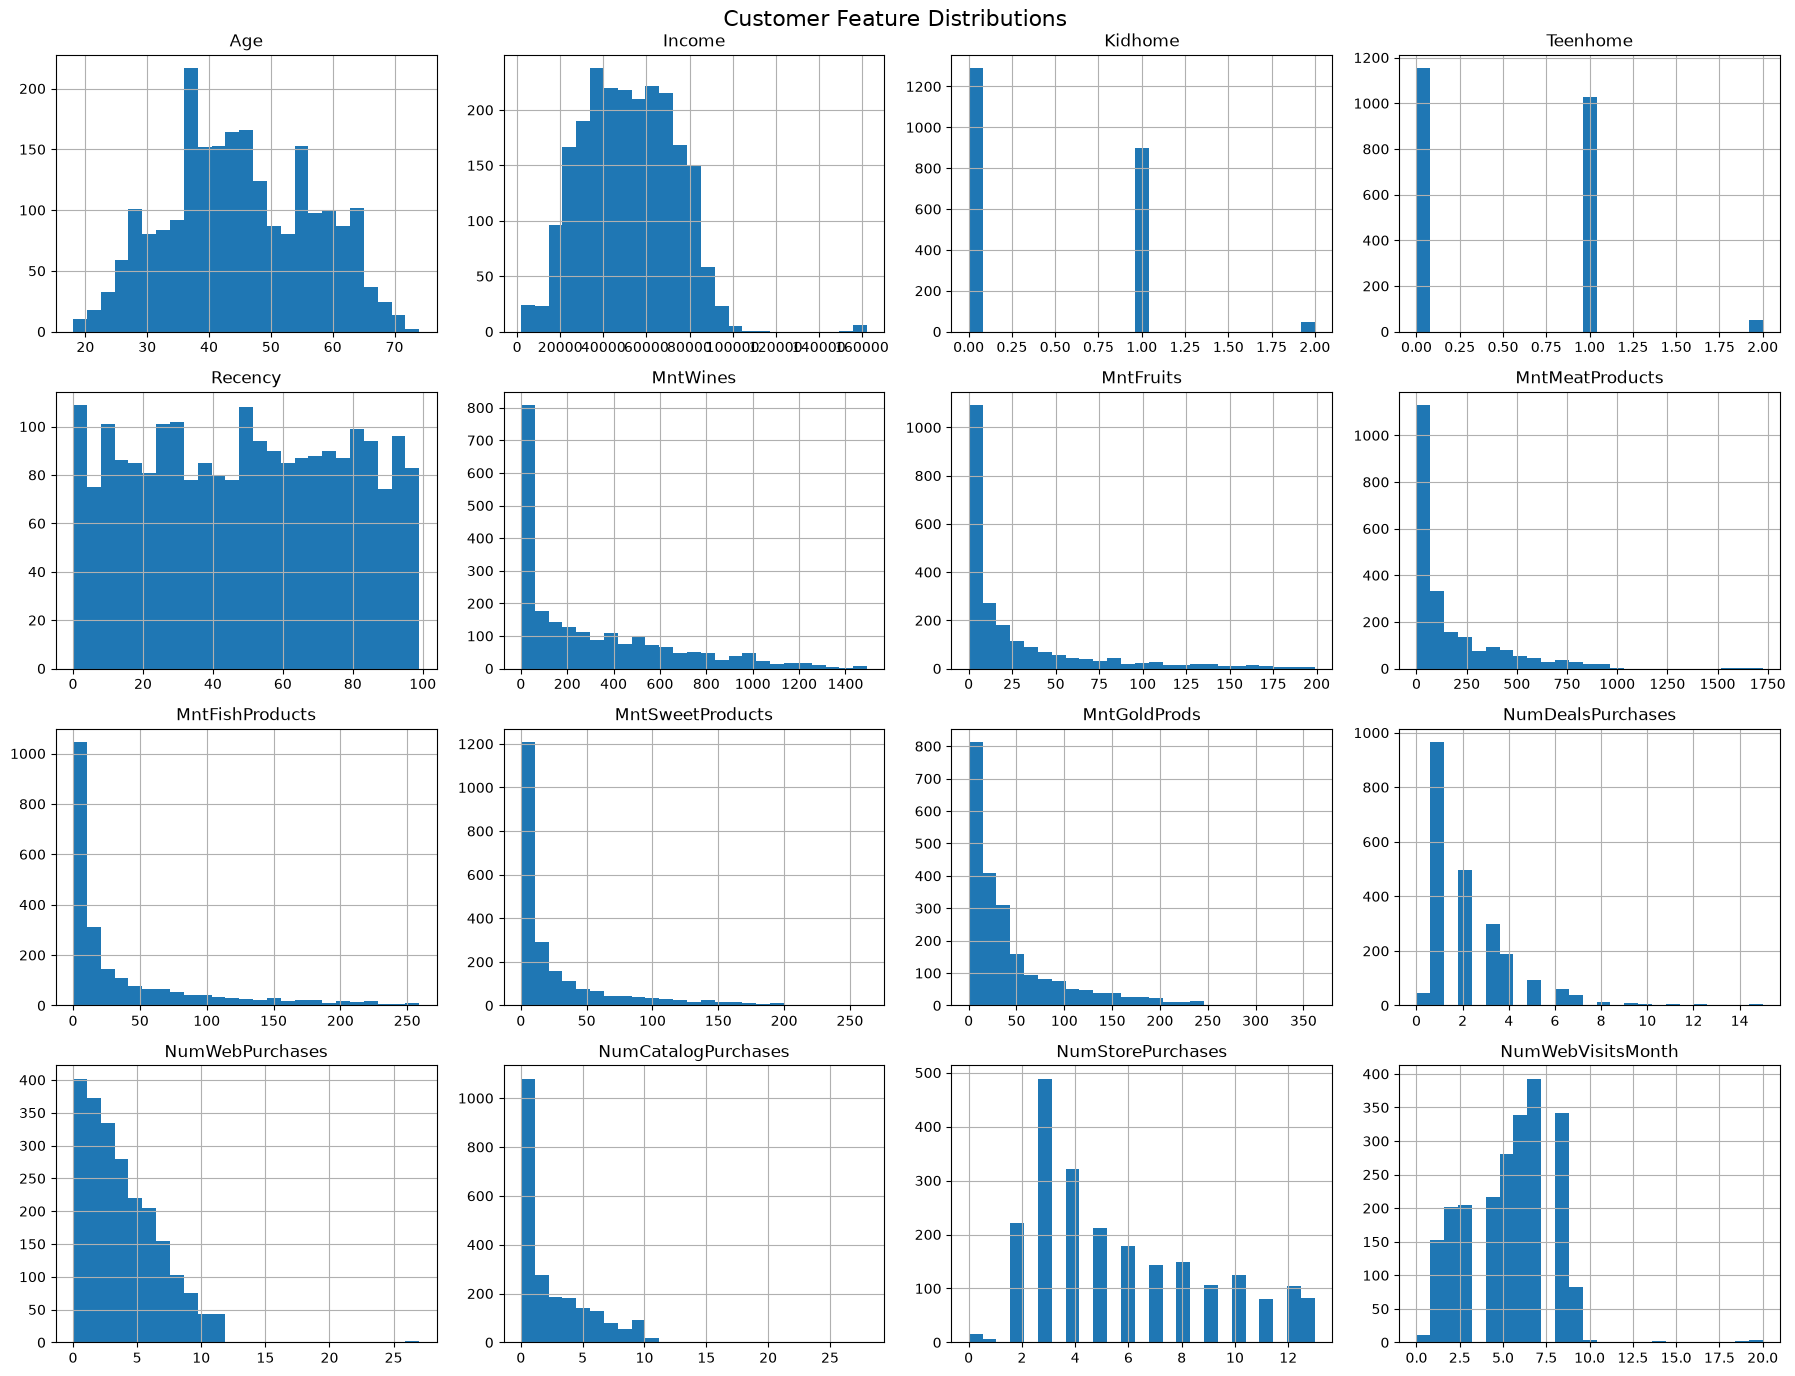

In [13]:
#Visualize feature distributions
X.hist(figsize=(18, 14), bins=25)

plt.suptitle('Customer Feature Distributions', fontsize=16)

plt.tight_layout()
plt.show()